In [1]:
import sys
import os
import matplotlib.pyplot as plt

In [2]:
def read_parameters(file_path):
    params = {}

    # First pass: read and store values as strings
    with open(file_path, 'r') as file:
        for line in file:
            # Skip empty lines and comments (if any)
            line = line.strip()
            if line and not line.startswith('#'):
                # Split the line at the equals sign
                key, value = line.split('=')
                key = key.strip()
                value = value.strip()

                # Store the parameter as a string for now
                params[key] = value

    # Second pass: evaluate expressions and convert values
    for key, value in params.items():
        try:
            # Try to evaluate the value as a Python expression using previously defined parameters
            params[key] = eval(value, {}, params)
        except:
            # If it's not an expression, check if it can be converted to float or int
            if '.' in value:
                params[key] = float(value)
            else:
                params[key] = int(value)
        
        # Set the variable in the global namespace with the evaluated value
        globals()[key] = params[key]

    return params

In [3]:
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "..")))
from ants_move import *
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "../..")))
from ddpg.buffer import *

pygame 2.5.2 (SDL 2.28.2, Python 3.10.12)
Hello from the pygame community. https://www.pygame.org/contribute.html


In [4]:
work_folder = 'trivia'
saving_folder = 'prova'
os.chdir(work_folder)

In [5]:
file_path = saving_folder + '/parameters.txt'  # Path to the parameters file
parameters = read_parameters(file_path)

for key, value in parameters.items():
    print(f"{key} = {value}")

n = 1
Lx = 25
Ly = 25
delta = 0.3
beta = 4.5
eta = 0.0
decay_rate = 0.015
eta_special = 1
n_special = 1
t_transient = 0
tmax = 30
batch_size = 25
gamma = 0.99
max_size = 1000000
state_dim = (1, 3, 3)
action_dim = 8
action_bound = 1
actor_lr = 1e-05
critic_lr = 0.0001
tau = 0.005
noise = 0.1
weight_decay = 0.0


In [6]:
env = Ants(n, Lx, Ly, delta, beta, decay_rate, eta, eta_special,
                  tmax, n_special, t_transient)

buffer = ReplayBuffer(max_size, state_dim, action_dim)

In [7]:
from ddpg_ants import *
config_net_file = f"{saving_folder}/networks.yaml"
ddpg_ants = DDPG_ants(env, buffer, gamma, action_bound, actor_lr, critic_lr, 
                                tau, batch_size, noise, weight_decay, config_net_file)

In [8]:
ddpg_ants.setup_networks()
ddpg_ants.load_weights(saving_folder + '/weights')

In [9]:
for key in ddpg_ants.critic.state_dict().keys():
    print(key)
    print(ddpg_ants.critic.state_dict()[key].sum())

cnn_layers.0.weight
tensor(-3.5657)
cnn_layers.0.bias
tensor(-0.1573)
cnn_layers.2.weight
tensor(32.0850)
cnn_layers.2.bias
tensor(-0.1763)
cnn_layers.2.running_mean
tensor(4.7182)
cnn_layers.2.running_var
tensor(0.4270)
cnn_layers.2.num_batches_tracked
tensor(11173)
action_layers.0.weight
tensor(-6.0681)
action_layers.0.bias
tensor(0.8448)
action_layers.1.weight
tensor(127.5091)
action_layers.1.bias
tensor(-0.3625)
action_layers.1.running_mean
tensor(-7.9848)
action_layers.1.running_var
tensor(83.7207)
action_layers.1.num_batches_tracked
tensor(11172)
fc_layers.0.weight
tensor(4.1535)
fc_layers.0.bias
tensor(0.0712)
fc_layers.2.weight
tensor(127.5486)
fc_layers.2.bias
tensor(0.5042)
fc_layers.2.running_mean
tensor(29.8499)
fc_layers.2.running_var
tensor(15.8646)
fc_layers.2.num_batches_tracked
tensor(11172)
output_layer.weight
tensor(-0.3680)
output_layer.bias
tensor(0.0765)


In [10]:
env.reset_objects()
env.transient()
trans_pos = env.positions.copy()
trans_pher = env.pheromones.copy()

results = ddpg_ants.test_episode()

In [11]:
mask = env.pheromones.T > env.s0

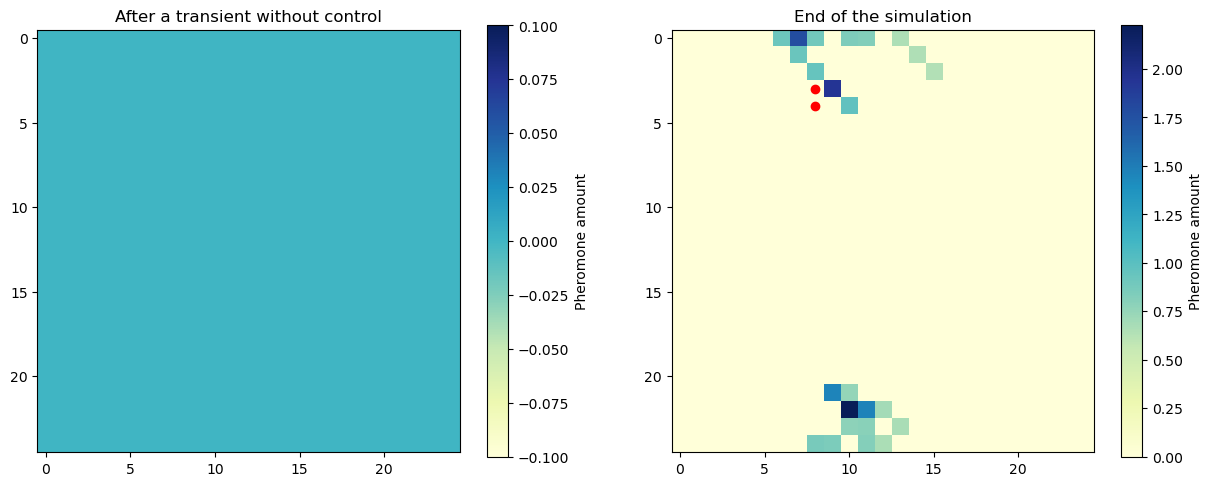

In [12]:
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(1,2,figsize=(15, 8))

im1 = ax[0].imshow(trans_pher.T, cmap='YlGnBu')
ax[0].scatter(np.array(trans_pos)[:-10,0],np.array(trans_pos)[:-10,1], c='orange')
ax[0].set_title('After a transient without control')
cbar1 = plt.colorbar(im1, ax=ax[0], shrink=0.7)
cbar1.set_label('Pheromone amount')

im2 = ax[1].imshow(env.pheromones.T, cmap='YlGnBu')
ax[1].scatter(np.array(env.positions)[:-10,0],np.array(env.positions)[:-10,1], c='orange')
ax[1].scatter(np.array(env.positions)[-10:,0],np.array(env.positions)[-10:,1], c='red')
#ax[1].scatter(np.array(env.positions)[-10:,0],np.array(env.positions)[-10:,1], c='black', marker='x')
ax[1].set_title('End of the simulation')

cbar2 = plt.colorbar(im2, ax=ax[1], shrink=0.7)
cbar2.set_label('Pheromone amount')

plt.savefig('trails.pdf')
plt.show()

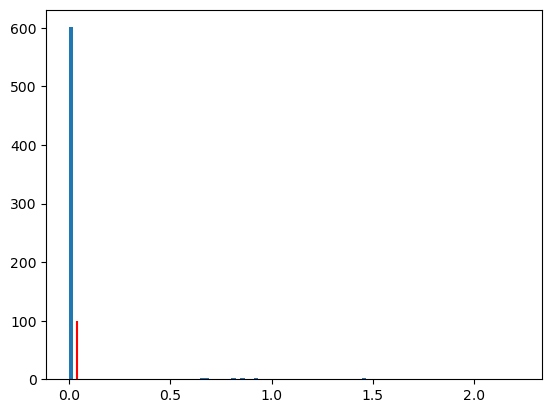

In [13]:
plt.hist(env.pheromones.flatten(), bins=100)
plt.vlines(env.s0, 0, 100, colors='red')

In [14]:
env.order_parameter_p()

-1.0

In [15]:
rewards = np.array(results[0])
actions = np.array(results[1])
states = np.array(results[2])

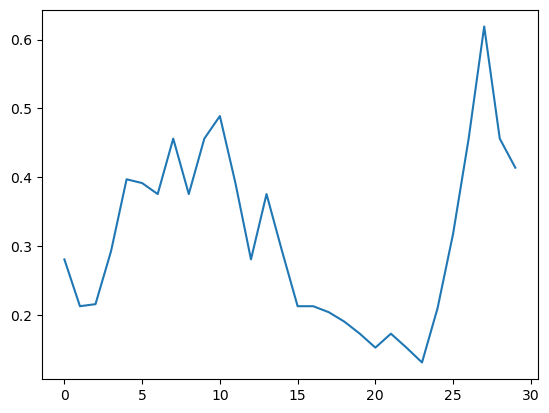

In [16]:
plt.plot(rewards[:,:,0])

In [17]:
# critic evaluation
vision = 3
value_list = []
best_action_list = []
avg_action_list = []
directions = env.directions
ddpg_ants.critic.eval()
ddpg_ants.actor.eval()
std_a = []

for i in range(env.Lx):
    for j in range(env.Ly):
        state = env.gauss[ddpg_ants.meshgrid(i, j)].reshape(1, vision, vision)
        state = torch.tensor(state, dtype=torch.float32).unsqueeze(0)
        action = ddpg_ants.actor(state)
        v = ddpg_ants.critic(state, action).detach().numpy()
        value_list.append(v)
        a = action.detach().numpy()[0,:]
        best_action_list.append(np.argmax(a))
        avg_action_list.append(np.sum(directions*a[:, np.newaxis], axis=0))
        std_a.append(np.std(a))

#field = directions[best_action_list]
field = avg_action_list

In [18]:
import torch.nn.functional as F
F.softmax(torch.tensor(a))

/tmp/ipykernel_75218/2399101714.py:2: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  F.softmax(torch.tensor(a))


tensor([0.1286, 0.1315, 0.1293, 0.1241, 0.1369, 0.1286, 0.1055, 0.1155])

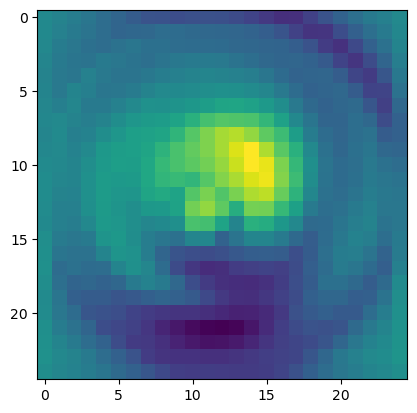

In [19]:
plt.imshow(np.array(value_list).reshape(env.Lx, env.Ly))

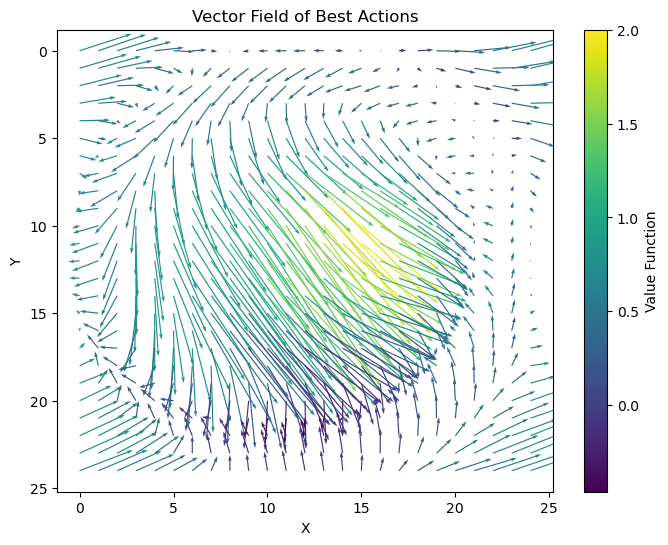

In [20]:
value_grid = np.array(value_list).reshape(env.Lx, env.Ly)
field = np.array(field).reshape(env.Lx, env.Ly, 2)

# Extract coordinates
X, Y = np.meshgrid(np.arange(env.Lx), np.arange(env.Ly))  # Grid positions
U, V = field[:, :, 0], field[:, :, 1]  # Vector components

# Plot the quiver plot
plt.figure(figsize=(8,6))
plt.quiver(X, Y, V, U, value_grid,  angles='xy', scale_units='xy', scale=0.1, cmap='viridis')
plt.colorbar(label="Value Function")
plt.xlabel("X")
plt.ylabel("Y")
plt.title("Vector Field of Best Actions")
plt.gca().invert_yaxis()  # Invert y-axis to match matrix indexing
plt.show()

ValueError: x and y can be no greater than 2-D, but have shapes (31,) and (31, 1, 3, 3)

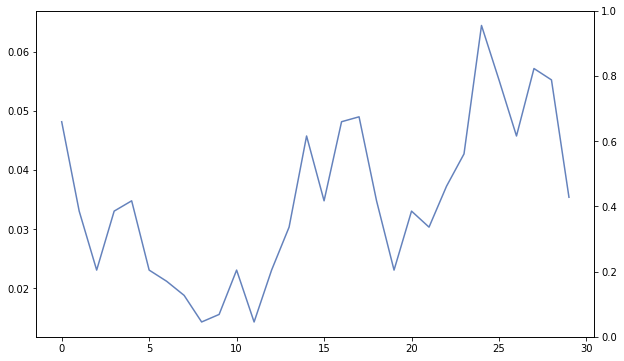

In [18]:
import matplotlib.cm as cm

fig, ax1 = plt.subplots(figsize=(10,6))

cmap = cm.get_cmap('YlGnBu')
cmap1 = cm.get_cmap('YlOrRd')

std_a_c = cmap(0.3) 
a_color = cmap(0.4)

std_r_c = cmap(0.7)
rew_color = cmap(0.8)

std_op_c = cmap1(0.7)
op_color = cmap1(0.8)
ax2 = ax1.twinx()

if work_folder == 'global':
    ax1.plot(rewards, label='Average Reward', c=rew_color, alpha=0.7)
    ax1.plot(states, label='Avreage Order Parameter', c=op_color, alpha=0.7)
    ax2.plot(actions*100, label='Average action', c=a_color, alpha=0.7)

else:
    ax1.plot(rewards[:,0], label='Average Reward', c=rew_color, alpha=0.7)
    ax1.plot(np.mean(states,axis=1), label='Avreage Order Parameter', c=op_color, alpha=0.7)
    ax2.plot(actions[:]*100, label='Average action', c=a_color, alpha=0.7)

ax1.grid()
ax1.legend(loc='upper left')
ax2.legend(loc='upper right')
#ax1.set_ylim(0,1.2)
ax1.set_xlabel('time')
ax2.tick_params(axis='y', labelcolor=cmap(0.5))
ax2.set_ylabel(r'$\eta^{\prime}/\eta$', color=cmap(0.5))
ax2.set_ylim(0, 200)
# plt.savefig('planner_learning.png')
plt.show()

In [ ]:
w = ddpg_ants.actor.state_dict()

In [ ]:
w['mu.bias']

In [ ]:
states.shape

In [ ]:
plt.scatter(np.array(states)[1:,:,0,1,1], actions)

In [ ]:
s = torch.FloatTensor(np.array([[0.1,0.2]]))
a = ddpg_ants.actor(s)
ddpg_ants.critic(s,a)

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

s1_list = np.linspace(0,1,21)
s2_list = np.linspace(0.0,0.2,21)

values = np.zeros((len(s1_list), len(s2_list)))

for i, s1 in enumerate(s1_list):
    for j, s2 in enumerate(s2_list):
        
        if work_folder == 'global':
            s = torch.FloatTensor(np.array([[s1,s2]]))
          
        else:
            s = torch.FloatTensor(np.array([[s1,0.1,s2]]))
            
        a = ddpg_ants.actor(s)
        values[i, j] = ddpg_ants.critic(s,a)

plt.figure(figsize=(10, 8))
sns.heatmap(values, xticklabels=np.round(s2_list, 3), yticklabels=np.round(s1_list, 3), cmap="coolwarm")

plt.xlabel("avgpher")
plt.ylabel("op")
plt.title("Heatmap critic DDPG")
plt.gca().invert_yaxis()
plt.show()

In [ ]:
s1_list = np.linspace(0.5,1,1)
a_list = np.linspace(0.0,0.4,21)

values = np.zeros((len(s1_list), len(s2_list)))

for i, s1 in enumerate(s1_list):
    for j, a in enumerate(a_list):
        
        if work_folder == 'global':
            s = torch.FloatTensor(np.array([[s1,0.1]]))
          
        else:
            s = torch.FloatTensor(np.array([[s1,0.1,0.1]]))
                      
        #a1 = ddpg_ants.actor(s)
        #print(a1)
        values[i, j] = ddpg_ants.critic(s,torch.FloatTensor([a*np.ones(10)]))

plt.figure(figsize=(10, 8))
sns.heatmap(values, xticklabels=np.round(a_list, 3), yticklabels=np.round(s1_list, 3), cmap="coolwarm")

plt.xlabel("actions")
plt.ylabel("stato loacl")
plt.title("Heatmap critic DDPG")
plt.gca().invert_yaxis()
plt.show()

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

trial_actions = np.linspace(0, 2, 21)
trial_states = np.linspace(0, 2, 21)

values = np.zeros((len(trial_actions), len(trial_states)))

for i, a in enumerate(trial_actions):
    for j, s in enumerate(trial_states):
        values[i, j] = ddpg_ants.critic(torch.FloatTensor(s.reshape(1,1)),torch.FloatTensor(a.reshape(1,1)))

plt.figure(figsize=(15, 10))
sns.heatmap(values, xticklabels=np.round(trial_states, 3), yticklabels=np.round(trial_actions, 3), cmap="coolwarm")

plt.xlabel("states")
plt.ylabel("actions")
plt.title("Heatmap critic DDPG")
plt.gca().invert_yaxis()
plt.show()

In [ ]:
plt.scatter(trial_states, trial_actions[np.argmax(values, axis=0)])
plt.scatter(trial_states, [ddpg_ants.policy(s.reshape(1,1), test=True) for s in trial_states])
#plt.scatter(state_list[1:], action_list)

In [ ]:
wc = ddpg_ants.critic.state_dict()

In [ ]:
print( wc['fc1.weight'].numpy().sum(),
wc['fc2.weight'].numpy().sum(),
wc['fc3.weight'].numpy().sum(),
wc['q.weight'].numpy().sum() )

In [ ]:
print( wc['fc1.bias'].numpy().sum(),
wc['fc2.bias'].numpy().sum(),
wc['fc3.bias'].numpy().sum(),
wc['q.bias'].numpy().sum() )

In [ ]:
ac = ddpg_ants.actor.state_dict()

In [ ]:
print( ac['fc1.weight'].numpy().sum(),
ac['fc2.weight'].numpy().sum(),
ac['fc3.weight'].numpy().sum(),
ac['mu.weight'].numpy().sum() )

In [ ]:
print( ac['fc1.bias'].numpy().sum(),
ac['fc2.bias'].numpy().sum(),
ac['fc3.bias'].numpy().sum(),
ac['mu.bias'].numpy().sum() )

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.colors as mcolors

# Normalize color mapping between 0 and 200
norm = mcolors.Normalize(vmin=0, vmax=np.max(actions) * 25)

# Set figure size
fig = plt.figure(figsize=(10, 6))

# Create 3D plot
ax = fig.add_subplot(111, projection='3d')

# Create 3D scatter plot and store the reference to use for the colorbar
scatter = ax.scatter3D(states[1:, 0, 0], states[1:, 0, 1], states[1:, 0, 2], 
                       c=np.array(actions[:,0]) * 25, cmap='YlGnBu', norm=norm)

# Add thin contour-like outline to each point
for i in range(1,len(states)):
    ax.plot([states[i, 0, 0]], [states[i, 0, 1]], [states[i, 0, 2]], 
            marker='o', markersize=6, markeredgecolor='black', markerfacecolor='none')

# Set axis labels
ax.set_xlabel('m')
ax.set_ylabel(r'$\langle \sigma \rangle$')
ax.set_zlabel(r'$\sigma_a$')
ax.set_xlim(-1, 1)
ax.set_ylim(0, np.max(states[:, 0, 1]))
ax.set_zlim(0, np.max(states[:, 0, 2]))

# Add colorbar with customized size and padding
cbar = fig.colorbar(scatter, ax=ax, fraction=0.025, pad=0.15)
cbar.set_label(r'$\eta^{\prime}/\eta$')

# Show plot
plt.show()

In [ ]:
import numpy as np
import multiprocessing
import time

# weight function
def phr_weight(sigma, delta, beta):
    return (1 + sigma/(1+delta*sigma))**beta 

class Example:
    def __init__(self, num):
        self.num = num
        self.pheromones = np.random.rand(num, 8)
        self.delta = np.random.rand(num)
        self.beta = np.random.rand(num)
        self.w = np.random.rand(num, 8)

    def sequential_execution(self):
        """Esecuzione sequenziale del ciclo"""
        p_ij = np.zeros((self.num, 8))
        for i in range(self.num):
            p_ij[i] = phr_weight(self.pheromones[i], self.delta[i], self.beta[i]) * self.w[i]
            p_ij[i] /= p_ij[i].sum()  # Normalizza le probabilità
        return p_ij

    def process_row(self, i):
        row = phr_weight(self.pheromones[i], self.delta[i], self.beta[i]) * self.w[i]
        return row / row.sum()

    def parallel_execution(self):
        """Esecuzione parallela con multiprocessing"""
        with multiprocessing.Pool(processes=multiprocessing.cpu_count()) as pool:
            results = pool.map(self.process_row, range(self.num))

        return np.array(results)

# Numero di elementi
num_elements = 100000  # Aumentare se necessario

# Creazione dell'oggetto
example = Example(num_elements)

# Test sequenziale
start = time.time()
example.sequential_execution()
end = time.time()
print(f"Esecuzione sequenziale: {end - start:.4f} secondi")

# Test parallelo
start = time.time()
example.parallel_execution()
end = time.time()
print(f"Esecuzione parallela: {end - start:.4f} secondi")

In [ ]:
import numpy as np
r = np.random.exponential(scale=10**(-20), size=100000)

In [ ]:
import matplotlib.pyplot as plt

In [ ]:
plt.hist(r)

In [ ]:
sum(r)